In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix

from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

import sys
import os
sys.path.insert(0, '../src')
from modeling import (
    cap_rare_categories, build_preprocessor, build_rf_model, build_pipeline,
    evaluate_model, extract_feature_importances, plot_feature_importance,
    aggregate_predictions_by_cell, get_orig_feature_name
)


In [2]:
master_path = "../data/processed/master_df.csv"
master_df = pd.read_csv(master_path)

# Make sure DATE is datetime
if 'DATE' in master_df.columns:
    master_df['DATE'] = pd.to_datetime(master_df['DATE'])


In [3]:
df_model = master_df.copy()

target_col = 'crash_tomorrow'

# Define categorical and numeric features explicitly
categorical_features = [
    'CountyNameTxt',
    'Region',
    'WeatherCde_txtCARTO',
    'SurfaceConditionCde_txtCARTO',
    'RdwyTypeCde_txtCARTO',
    'day_of_week',
]

numeric_features = [
    'TAVG_MEDIAN',
    'PRCP_MEDIAN',
    'SNOW_MEDIAN',
    'WT01_MAX',
    'WT02_MAX',
    'WT03_MAX',
    'WT04_MAX',
    'WT05_MAX',
    'WT06_MAX',
    'WT08_MAX',
    'WT09_MAX',
    'day_of_year',
    'month',
]

# Combine all features
feature_cols = categorical_features + numeric_features

# Verify all features exist in the dataframe
missing_features = [f for f in feature_cols if f not in df_model.columns]
if missing_features:
    print(f"WARNING: Missing features: {missing_features}")
else:
    print(f"All {len(feature_cols)} features found in dataframe")

print(f"\nCategorical features ({len(categorical_features)}): {categorical_features}")
print(f"\nNumeric features ({len(numeric_features)}): {numeric_features}")


All 19 features found in dataframe

Categorical features (6): ['CountyNameTxt', 'Region', 'WeatherCde_txtCARTO', 'SurfaceConditionCde_txtCARTO', 'RdwyTypeCde_txtCARTO', 'day_of_week']

Numeric features (13): ['TAVG_MEDIAN', 'PRCP_MEDIAN', 'SNOW_MEDIAN', 'WT01_MAX', 'WT02_MAX', 'WT03_MAX', 'WT04_MAX', 'WT05_MAX', 'WT06_MAX', 'WT08_MAX', 'WT09_MAX', 'day_of_year', 'month']


In [4]:
# Ensure DATE is datetime (safe to run again)
df_model['DATE'] = pd.to_datetime(df_model['DATE'])

# Create temporal split: data through 2023 for training, 2024 for testing
train_mask = df_model['DATE'].dt.year <= 2023
test_mask  = df_model['DATE'].dt.year > 2023

X_train = df_model.loc[train_mask, feature_cols]
y_train = df_model.loc[train_mask, target_col]

X_test = df_model.loc[test_mask, feature_cols]
y_test = df_model.loc[test_mask, target_col]

print("Train size:", X_train.shape, "Test size:", X_test.shape)
print(f"Positive rate in train: {y_train.mean():.4f}")
print(f"Positive rate in test: {y_test.mean():.4f}")


Train size: (374896, 19) Test size: (76257, 19)
Positive rate in train: 0.0581
Positive rate in test: 0.0540


In [5]:
# Reset indices to align X and y properly for pipeline fitting
X_train_reset = X_train.reset_index(drop=True)
y_train_reset = y_train.reset_index(drop=True)
X_test_reset = X_test.reset_index(drop=True)
y_test_reset = y_test.reset_index(drop=True)


## Faster preprocessing: cap infrequent categories
Cap infrequent categories to `OTHER` before one-hot encoding to reduce the number of dummy columns and speed up preprocessing.


In [6]:
# Cap rare categories to reduce one-hot dimensionality
# Use the categorical_features list defined earlier
X_capped = cap_rare_categories(df_model, categorical_features, top_n=30)

# Recompute splits with capped categories
X_capped_train = X_capped.loc[train_mask, feature_cols]
X_capped_test  = X_capped.loc[test_mask, feature_cols]

y_train_reset = y_train.reset_index(drop=True)
y_test_reset  = y_test.reset_index(drop=True)

print("Capping complete. Example categories after capping:")
for c in categorical_features[:3]:
    print(f"  {c}: {X_capped[c].nunique()} unique (was {df_model[c].nunique()})")


Capping complete. Example categories after capping:
  CountyNameTxt: 20 unique (was 20)
  Region: 5 unique (was 5)
  WeatherCde_txtCARTO: 9 unique (was 9)


## Build preprocessor and train a balanced RF
Use the capped categories, sparse one-hot, and class-balanced RandomForest.

In [7]:
# Build preprocessor with sparse output and RF baseline model
preprocessor_fast = build_preprocessor(numeric_features, categorical_features, sparse=True)
rf_baseline = build_rf_model(n_estimators=200, max_depth=None, min_samples_leaf=2, max_features='sqrt')
pipeline_baseline = build_pipeline(preprocessor_fast, rf_baseline)

# Fit on capped data
pipeline_baseline.fit(X_capped_train, y_train_reset)

# Quick evaluation on baseline
y_prob_baseline = pipeline_baseline.predict_proba(X_capped_test)[:, 1]
y_pred_baseline = (y_prob_baseline >= 0.5).astype(int)

metrics_baseline = evaluate_model(y_test_reset, y_prob_baseline, y_pred_baseline)
print("Baseline RF results (full training data, capped categories):")
print(f"  ROC AUC: {metrics_baseline['auc']:.4f}")
print(f"  Sensitivity: {metrics_baseline['sensitivity']:.4f}")
print(f"  Specificity: {metrics_baseline['specificity']:.4f}")


Baseline RF results (full training data, capped categories):
  ROC AUC: 0.6488
  Sensitivity: 0.1242
  Specificity: 0.9492


## Create a small tuning set (using 10% of training)
For faster RandomizedSearchCV, use only the most recent 10% of training data while keeping the rest for final refit.


In [8]:
# Create a cheap tuning set from recent history (last 10% of training data)
# This allows fast RandomizedSearchCV iterations while full refit uses all training data

tune_split_idx = int(0.9 * len(X_capped_train))

X_tune = X_capped_train.iloc[tune_split_idx:].reset_index(drop=True)
y_tune = y_train_reset.iloc[tune_split_idx:].reset_index(drop=True)

print(f"Full training set size: {len(X_capped_train)}")
print(f"Tune set size (recent 10%): {len(X_tune)}")
print(f"Tune set positive rate: {y_tune.mean():.4f}")
print(f"Test set positive rate: {y_test_reset.mean():.4f}")


Full training set size: 374896
Tune set size (recent 10%): 37490
Tune set positive rate: 0.0511
Test set positive rate: 0.0540


## Tune on small set with RandomizedSearchCV
Run hyperparameter search on the recent 10% tuning set to find the best configuration quickly.


In [9]:
# Setup hyperparameter search space
param_dist = {
    'rf__n_estimators': [200, 400, 600],
    'rf__max_depth': [None, 10, 20],
    'rf__min_samples_leaf': [1, 2, 4],
    'rf__max_features': ['sqrt', 'log2'],
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Use pipeline_baseline as the template for hyperparameter search
search = RandomizedSearchCV(
    estimator=pipeline_baseline,
    param_distributions=param_dist,
    n_iter=10,
    scoring='roc_auc',
    n_jobs=-1,
    cv=cv,
    verbose=1,
    random_state=42,
    refit=False  # Don't refit yet, do it on full training data
)

# Tune on the cheap recent set
search.fit(X_tune, y_tune)

print("Best params (from tuning set):")
print(search.best_params_)
print(f"Best CV ROC AUC (tuning set): {search.best_score_:.4f}")


Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best params (from tuning set):
{'rf__n_estimators': 600, 'rf__min_samples_leaf': 2, 'rf__max_features': 'log2', 'rf__max_depth': 10}
Best CV ROC AUC (tuning set): 0.6635


## Refit best model on full training history
Extract the best hyperparameters from tuning, create a fresh pipeline, and refit on all available training data (not just the tuning subset).


In [10]:
# Extract best hyperparameters from search
best_params = search.best_params_

# Create a fresh RF with the best params
rf_final = build_rf_model(
    n_estimators=int(best_params['rf__n_estimators']),
    max_depth=best_params['rf__max_depth'],
    min_samples_leaf=int(best_params['rf__min_samples_leaf']),
    max_features=best_params['rf__max_features']
)

# Refit the entire pipeline on full training data
pipeline_final = build_pipeline(preprocessor_fast, rf_final)

# Refit on full training set (not just tuning subset)
pipeline_final.fit(X_capped_train, y_train_reset)

print("Final model refitted on full training data.")
print(f"Training set size: {len(X_capped_train)}")
print(f"Best params: {best_params}")


Final model refitted on full training data.
Training set size: 374896
Best params: {'rf__n_estimators': 600, 'rf__min_samples_leaf': 2, 'rf__max_features': 'log2', 'rf__max_depth': 10}


## Final evaluation on untouched test window
Evaluate the final refitted model on the holdout test set (completely untouched throughout tuning and refit).


In [11]:
# Predict on final holdout test set
y_prob_final = pipeline_final.predict_proba(X_capped_test)[:, 1]
y_pred_final = (y_prob_final >= 0.5).astype(int)

# Evaluate with our evaluation function
metrics_final = evaluate_model(y_test_reset, y_prob_final, y_pred_final)
auc_final = metrics_final['auc']

print("="*80)
print("FINAL MODEL PERFORMANCE (on untouched test set)")
print("="*80)
print(f"ROC AUC: {auc_final:.4f}")
print(f"Sensitivity: {metrics_final['sensitivity']:.4f}")
print(f"Specificity: {metrics_final['specificity']:.4f}")
print("\nClassification Report:")
print(metrics_final['classification_report'])
print("\nConfusion Matrix:")
cm = metrics_final['confusion_matrix']
print(cm)

tn, fp, fn, tp = cm.ravel()
print(f"\nTrue Negatives:  {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives:  {tp}")
print("="*80)


FINAL MODEL PERFORMANCE (on untouched test set)
ROC AUC: 0.6653
Sensitivity: 0.5757
Specificity: 0.6481

Classification Report:
              precision    recall  f1-score   support

         0.0       0.96      0.65      0.78     72142
         1.0       0.09      0.58      0.15      4115

    accuracy                           0.64     76257
   macro avg       0.52      0.61      0.46     76257
weighted avg       0.92      0.64      0.74     76257


Confusion Matrix:
[[46754 25388]
 [ 1746  2369]]

True Negatives:  46754
False Positives: 25388
False Negatives: 1746
True Positives:  2369


## Score all rows with final model and aggregate by cell
Generate risk predictions for all data rows and rank cells by average predicted crash probability.


In [12]:
# Score all rows and aggregate by cell
X_capped_all = cap_rare_categories(df_model, categorical_features, top_n=30)
# Use only the feature columns for prediction to avoid scikit-learn feature name mismatch errors
all_probs = pipeline_final.predict_proba(X_capped_all[feature_cols])[:, 1]

# Use the aggregation function from modeling.py
risk_by_cell_final = aggregate_predictions_by_cell(
    df_model, 
    cell_col='cell_id',
    predictions=all_probs
)

print("Top 10 highest-risk cells (final model):")
print(risk_by_cell_final.head(10))
print(f"\nTotal cells scored: {len(risk_by_cell_final)}")


Top 10 highest-risk cells (final model):
      cell_id  pred_crash_prob
5311   153_78         0.655810
2441  128_152         0.648517
5000   150_96         0.648033
4917  150_119         0.647855
4911  150_113         0.645229
8431   176_78         0.642722
4913  150_115         0.640730
3334  136_146         0.640685
4999   150_95         0.640448
4727  149_102         0.639863

Total cells scored: 21965


## Feature Importance Analysis
Analyze and visualize which features contribute most to the final model's predictions.


Top 15 Most Important Features (aggregated by original feature name):
orig_feature
RdwyTypeCde_txtCARTO_Interstate Trunk Highway - ISTH    0.182396
CountyNameTxt_HENNEPIN                                  0.141934
Region_Metro                                            0.063489
TAVG_MEDIAN                                             0.059641
Region_East Central                                     0.044995
RdwyTypeCde_txtCARTO_County State Aid Highway - CSAH    0.034160
CountyNameTxt_DAKOTA                                    0.028295
day_of_year                                             0.028268
CountyNameTxt_WASHINGTON                                0.028007
RdwyTypeCde_txtCARTO_Local (or City) Street - MUN       0.026856
CountyNameTxt_CARVER                                    0.020964
RdwyTypeCde_txtCARTO_Ramp or Connector                  0.018949
CountyNameTxt_SHERBURNE                                 0.018808
CountyNameTxt_RAMSEY                                    0.017490
CountyN

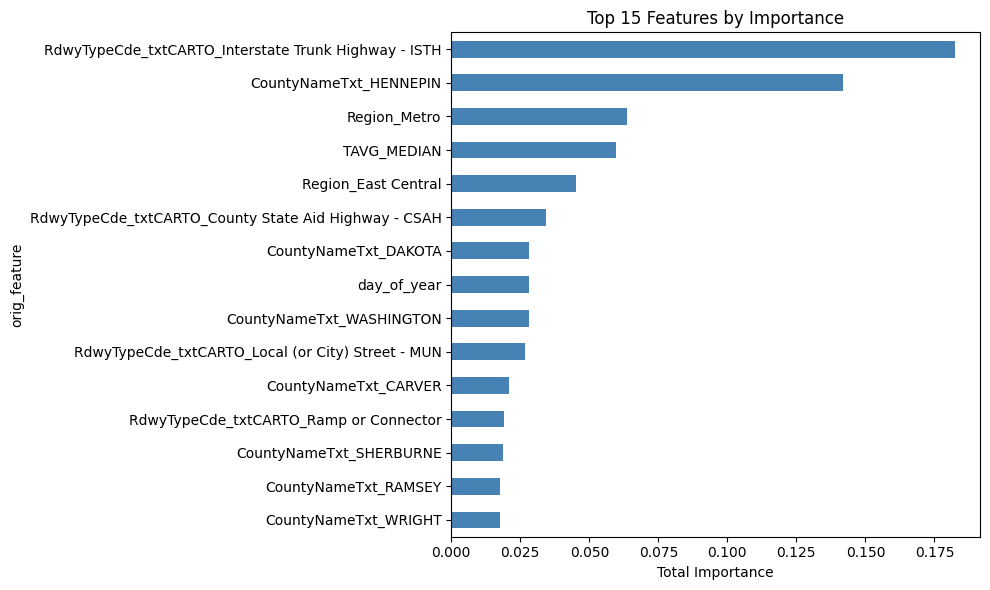


Top 20 Individual Features (one-hot encoded):
                                              feature  importance
66  RdwyTypeCde_txtCARTO_Interstate Trunk Highway ...    0.182396
19                             CountyNameTxt_HENNEPIN    0.141934
34                                       Region_Metro    0.063489
0                                    num__TAVG_MEDIAN    0.059641
33                                Region_East Central    0.044995
62  RdwyTypeCde_txtCARTO_County State Aid Highway ...    0.034160
17                               CountyNameTxt_DAKOTA    0.028295
11                                   num__day_of_year    0.028268
31                           CountyNameTxt_WASHINGTON    0.028007
67  RdwyTypeCde_txtCARTO_Local (or City) Street - MUN    0.026856
15                               CountyNameTxt_CARVER    0.020964
81             RdwyTypeCde_txtCARTO_Ramp or Connector    0.018949
28                            CountyNameTxt_SHERBURNE    0.018808
25                           

In [13]:
# Extract feature importances using the modeling.py function
fi_df, grouped_importance = extract_feature_importances(pipeline_final, feature_cols)

print("Top 15 Most Important Features (aggregated by original feature name):")
print(grouped_importance.head(15))

# Visualize top features using the modeling.py function
plot_feature_importance(grouped_importance, top_n=15, figsize=(10, 6))

# Show individual feature importances for top 20
print("\nTop 20 Individual Features (one-hot encoded):")
print(fi_df.head(20)[['feature', 'importance']])


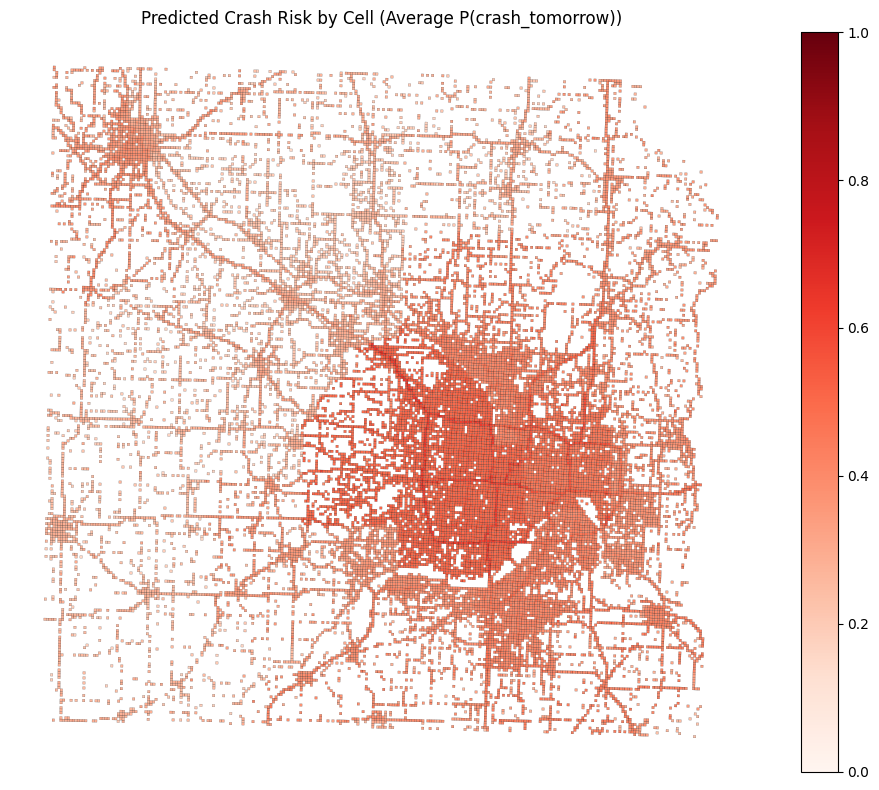

In [14]:
import geopandas as gpd

grid_path = "../data/processed/grid.gpkg"  # or whatever you used
grid = gpd.read_file(grid_path)

risk_gdf = grid.merge(risk_by_cell_final, on='cell_id', how='left')

fig, ax = plt.subplots(1, 1, figsize=(10, 8))

risk_gdf.plot(
    column='pred_crash_prob',
    cmap='Reds',
    legend=True,
    ax=ax,
    edgecolor='black',
    linewidth=0.1,
    vmin=0,  
    vmax=1.0,  
)

ax.set_title("Predicted Crash Risk by Cell (Average P(crash_tomorrow))")
ax.set_axis_off()
plt.tight_layout()
plt.show()
